# 9-ЗЖ. Ағын метрикалары

Деректер — тақтадағы уақыттар (`sprint-data.csv`): әр тапсырманың «Жұмысқа алынды», «Тексеруге берілді», «Дайын болды» уақыты. Спринттер курс кестесінен артта қалғандықтан бірнеше сағатқа қысқартылды, сондықтан метрикалар минутпен есептеледі.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
SPRINTS = {                      # спринттің басталу және аяқталу уақыты
    '1-спринт': ('2026-11-03 08:00', '2026-11-03 08:20'),
    '2-спринт': ('2026-11-03 14:30', '2026-11-03 14:36'),
}
df = pd.read_csv('sprint-data.csv')
for c in ['Жұмысқа алынды', 'Тексеруге берілді', 'Дайын болды']:
    df[c] = pd.to_datetime(df[c], errors='coerce')
df

,Тапсырма,Спринт,Жұмысқа алынды,Тексеруге берілді,Дайын болды
0,T1 ADR-002,1-спринт,2026-11-03 08:00:00,2026-11-03 08:05:00,2026-11-03 08:10:00
1,T2 Жоба қаңқасы,1-спринт,2026-11-03 08:05:00,2026-11-03 08:08:00,2026-11-03 08:11:00
2,T3 ZHL-17 Қызметтер,1-спринт,2026-11-03 08:10:00,2026-11-03 08:12:00,2026-11-03 08:13:00
3,T4 ZHL-13 Жұмыс кестесі,1-спринт,2026-11-03 08:12:00,2026-11-03 08:13:00,2026-11-03 08:15:00
4,T5 Іске қосу нұсқаулығы,1-спринт,2026-11-03 08:16:00,2026-11-03 08:18:00,2026-11-03 08:20:00
5,T6 ZHL-28 Жазылу,2-спринт,2026-11-03 14:30:00,2026-11-03 14:31:00,2026-11-03 14:34:00
6,T7 ZHL-27 Статус,2-спринт,2026-11-03 14:32:00,2026-11-03 14:32:00,2026-11-03 14:35:00
7,T8 ZHL-12 Күнтізбе көрінісі,2-спринт,2026-11-03 14:34:00,2026-11-03 14:35:00,2026-11-03 14:36:00


## Throughput, cycle time, тексеруді күту

Cycle time — «Жұмысқа алынды» уақытынан «Дайын болды» уақытына дейін, минутпен. Тексеру кезеңі — «Тексеруге берілді» уақытынан «Дайын болды» уақытына дейін (күту + тексеру).

In [2]:
H = pd.Timedelta(minutes=1)
df['Cycle time, мин'] = (df['Дайын болды'] - df['Жұмысқа алынды']) / H
df['Тексеру кезеңі, мин'] = (df['Дайын болды'] - df['Тексеруге берілді']) / H
rows = []
for name, (a, b) in SPRINTS.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    done = df[(df['Дайын болды'] >= a) & (df['Дайын болды'] <= b)]
    ct = done['Cycle time, мин']
    rows.append({
        'Спринт': name,
        'Throughput (жабылды)': len(done),
        'Орташа cycle time, мин': round(ct.mean(), 1) if len(ct) else None,
        'p85 cycle time, мин': round(float(np.percentile(ct, 85)), 1) if len(ct) else None,
        'Тексеру кезеңінің үлесі, %': round(100 * done['Тексеру кезеңі, мин'].sum() / ct.sum()) if ct.sum() else None,
    })
summary = pd.DataFrame(rows); summary

,Спринт,Throughput (жабылды),"Орташа cycle time, мин","p85 cycle time, мин","Тексеру кезеңінің үлесі, %"
0,1-спринт,5,5.2,7.6,50
1,2-спринт,3,3.0,3.7,78


## Кумулятивтік ағын диаграммасы (CFD)

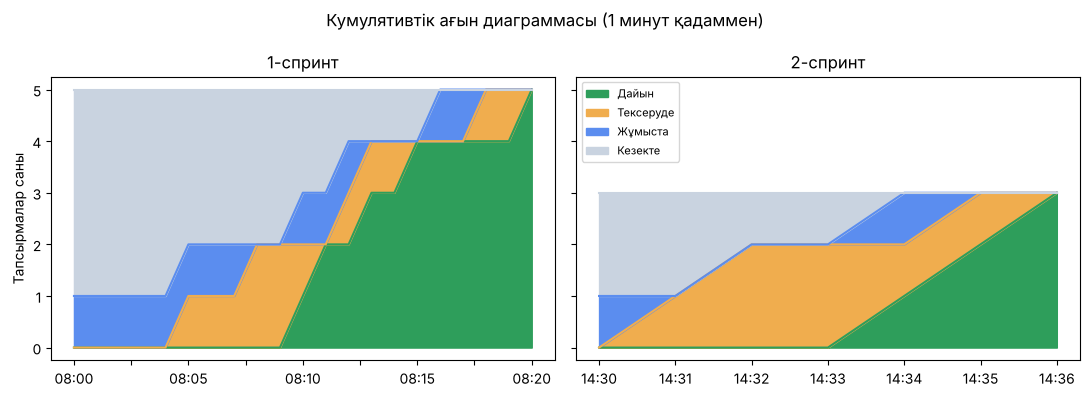

In [3]:
fig, axes = plt.subplots(1, len(SPRINTS), figsize=(11, 4), sharey=True)
for ax, (name, (a, b)) in zip(np.atleast_1d(axes), SPRINTS.items()):
    part = df[df['Спринт'] == name]
    steps = pd.date_range(pd.Timestamp(a), pd.Timestamp(b), freq='1min')
    rows = []
    for d in steps:
        dn = (part['Дайын болды'] <= d).sum()
        rv = (part['Тексеруге берілді'] <= d).sum() - dn
        wk = (part['Жұмысқа алынды'] <= d).sum() - dn - rv
        rows.append((d, dn, rv, wk, len(part) - dn - rv - wk))
    c = pd.DataFrame(rows, columns=['t', 'Дайын', 'Тексеруде', 'Жұмыста', 'Кезекте']).set_index('t')
    c.index = c.index.strftime('%H:%M')
    c.plot.area(ax=ax, color=['#2e9e5b', '#f0ad4e', '#5b8def', '#c9d3e0'], legend=False)
    ax.set_title(name); ax.set_xlabel('')
axes = np.atleast_1d(axes); axes[0].set_ylabel('Тапсырмалар саны'); axes[-1].legend(loc='upper left', fontsize=8)
fig.suptitle('Кумулятивтік ағын диаграммасы (1 минут қадаммен)')
plt.tight_layout(); plt.savefig('cfd.png', dpi=150); plt.show()

## Аяқталмаған жұмыстың жасы (әр спринт соңында)

In [4]:
for name, (a, b) in SPRINTS.items():
    b = pd.Timestamp(b)
    open_ = df[(df['Жұмысқа алынды'] <= b) & ~(df['Дайын болды'] <= b)]
    print(name, '— аяқталмаған:', len(open_))
    for _, t in open_.iterrows():
        print('  ', t['Тапсырма'], '—', round((b - t['Жұмысқа алынды']) / pd.Timedelta(minutes=1)), 'мин')

1-спринт — аяқталмаған: 0
2-спринт — аяқталмаған: 0
